# 02 · Semantic Item Embeddings

Milestone 2 of the hands-on track. Goals:
- encode each item's text (title, brand, categories, price) with a sentence-transformer
- check that the embedding space is meaningful: neighbours, categories, and consecutive purchases
- use it directly as a recommender (**semantic item-kNN**) and compare with milestone 1

These embeddings are the input to the Semantic ID tokenizers in milestones 3–4.

Build them first: `python scripts/embed_items.py` (sentence-t5-base, ~768-d).

In [1]:
import os
os.chdir('..')  # run from repo root

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from genrec.data.amazon import load_processed
from genrec.data.sequences import leave_one_out
from genrec.embeddings.text import embeddings_path
from genrec.metrics import evaluate
from genrec.models.baselines import SemanticKNN

sequences, items = load_processed('data/processed/beauty')
emb = np.load(embeddings_path('data/processed/beauty'))
train, valid, test = leave_one_out(sequences)
print('embeddings:', emb.shape, '| norms:', np.linalg.norm(emb[1:], axis=1).round(3).min(), 'to',
      np.linalg.norm(emb[1:], axis=1).round(3).max())
print('example text:', items.loc[1, 'text'])

embeddings: (12102, 768) | norms: 1.0 to 1.0
example text: Title: WAWO 15 Color Professionl Makeup Eyeshadow Camouflage Facial Concealer Neutral Palette. Brand: COKA. Categories: Beauty, Makeup, Face, Concealers & Neutralizers. Price: $5.04


## Nearest neighbours
Cosine similarity = dot product, since the vectors are L2-normalized.

In [2]:
def neighbours(i, n=5):
    sims = emb @ emb[i]
    sims[[0, i]] = -np.inf
    top = np.argsort(-sims)[:n]
    return pd.DataFrame({'sim': sims[top].round(3), 'title': items.loc[top, 'title'].str[:80].values}, index=top)

rng = np.random.default_rng(0)
for i in rng.choice(np.arange(1, len(emb)), 3, replace=False):
    print(f'\n[{i}] {items.loc[i, "title"][:90]}')
    print(neighbours(i).to_string())


[7708] Konad Stamping Nail Art Special Polish Princcess Line Gold Black+white 12 Ml +swisa nail b
         sim                                                                             title
11147  0.933  Kleancolor Nail Polish CHUNKY HOLO + NABI Matte White Lot of 10 Lacquer + Free E
11410  0.932  KLEANCOLOR METALLIC COLLETION 12 PCS FULL SET - NAIL POLISH LACQUER + FREE EARRI
11421  0.930  Bundle Monster 25pc Holiday Collection Nail Art Image Polish Stamping Plates Man
3956   0.929                                             Konad Nail Art Stamping Polish - Gold
10594  0.927  15 Pcs Nail Art Design Painting Polish Brushes Dotting Drawing Pen Manicure Pedi

[6186] All Eyes on You Eyelash &amp; Brow Enhancing Serum, 3 ml
         sim                                                                             title
10315  0.950              RapidLash Eyelash and Eyebrow Enhancing Serum, 3 ml, 0.1 Fluid Ounce
6053   0.950                                               SmartLash Eyelash

## Does the space line up with categories?
Share of each item's 10 nearest neighbours that have the same leaf category, versus 10 random items.

In [3]:
leaf = items['categories'].str.split(' \| ').str[0].str.split(', ').str[-1]
leaf_arr = np.concatenate([[''], leaf.values])  # row 0 = padding

sample = rng.choice(np.arange(1, len(emb)), 2000, replace=False)
sims = emb[sample] @ emb.T
sims[:, 0] = -np.inf
sims[np.arange(len(sample)), sample] = -np.inf
nn = np.argpartition(-sims, 10, axis=1)[:, :10]
same_nn = (leaf_arr[nn] == leaf_arr[sample][:, None]).mean()
rand = rng.integers(1, len(emb), size=(len(sample), 10))
same_rand = (leaf_arr[rand] == leaf_arr[sample][:, None]).mean()
print(f'{leaf.nunique()} leaf categories')
print(f'same leaf category: 10-NN {same_nn:.1%} vs random {same_rand:.1%}')

<>:1: SyntaxWarning: invalid escape sequence '\|'
<>:1: SyntaxWarning: invalid escape sequence '\|'
/var/folders/qr/1hmxmjpn2jg6xqfy7vkrgsb80000gn/T/ipykernel_75042/459264165.py:1: SyntaxWarning: invalid escape sequence '\|'
  leaf = items['categories'].str.split(' \| ').str[0].str.split(', ').str[-1]


220 leaf categories
same leaf category: 10-NN 51.9% vs random 2.0%


## Are consecutive purchases semantically close?
If a user's next item tends to be close to their last one, then a content-only recommender has signal to work with. Compare cosine(last, next) over training sequences with random item pairs.

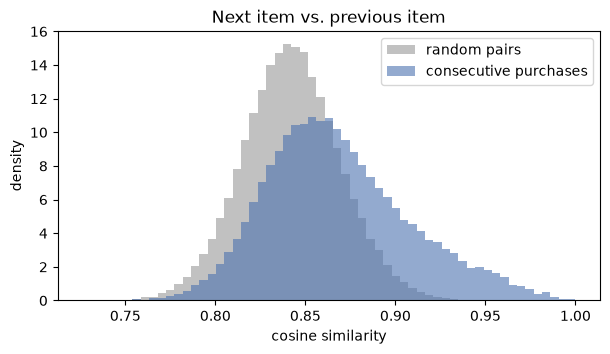

median cosine: consecutive 0.864 vs random 0.842


In [4]:
pairs = np.array([(s[j], s[j + 1]) for s in train for j in range(len(s) - 1) if s[j] != s[j + 1]])
consecutive = (emb[pairs[:, 0]] * emb[pairs[:, 1]]).sum(1)
rand_pairs = rng.integers(1, len(emb), size=(len(pairs), 2))
random_sim = (emb[rand_pairs[:, 0]] * emb[rand_pairs[:, 1]]).sum(1)

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(min(consecutive.min(), random_sim.min()), 1, 60)
ax.hist(random_sim, bins=bins, alpha=0.6, density=True, label='random pairs', color='#999999')
ax.hist(consecutive, bins=bins, alpha=0.6, density=True, label='consecutive purchases', color='#4C72B0')
ax.set(xlabel='cosine similarity', ylabel='density', title='Next item vs. previous item')
ax.legend()
plt.show()
print(f'median cosine: consecutive {np.median(consecutive):.3f} vs random {np.median(random_sim):.3f}')

## Semantic item-kNN
Profile = recency-weighted sum of the last `n_recent` item embeddings (weight `decay**age`); rank the catalog by cosine similarity, skipping items already in the history.

Small sweep on the **validation** split only, so the test split stays untouched.

In [5]:
rows = []
for n_recent in [1, 3, 5, 10]:
    for decay in [0.3, 0.5, 0.8, 1.0]:
        if n_recent == 1 and decay != 1.0:
            continue  # decay has no effect with one item
        model = SemanticKNN(emb, n_recent, decay)
        m = evaluate(model.recommend(valid[0], 10), valid[1], [10])
        rows.append({'n_recent': n_recent, 'decay': decay, **m})
sweep = pd.DataFrame(rows).sort_values('ndcg@10', ascending=False)
sweep.round(4)

,n_recent,decay,recall@10,ndcg@10,mrr
9,10,0.3,0.0609,0.0359,0.0283
5,5,0.3,0.0609,0.0359,0.0283
1,3,0.3,0.0606,0.0359,0.0283
0,1,1.0,0.0588,0.0350,0.0277
2,3,0.5,0.0595,0.0347,0.0271
6,5,0.5,0.0594,0.0346,0.0270
10,10,0.5,0.0594,0.0346,0.0270
3,3,0.8,0.0541,0.0305,0.0233
7,5,0.8,0.0492,0.0273,0.0206
11,10,0.8,0.0469,0.0262,0.0199


## Results so far
Test-split metrics from the latest `scripts/train.py` run of each config (`configs/semantic_knn_beauty.yaml` uses the defaults n_recent=5, decay=0.5).

In [6]:
def latest(name):
    run = sorted(Path('experiments').glob(f'{name}-*'))[-1]
    return json.loads((run / 'metrics.json').read_text())['test']

names = {'Popularity': 'popularity_beauty', 'Semantic kNN': 'semantic_knn_beauty', 'SASRec': 'sasrec_beauty'}
pd.DataFrame({label: latest(n) for label, n in names.items()}).T[
    ['recall@10', 'ndcg@10', 'recall@20', 'ndcg@20', 'mrr']
].round(4)

,recall@10,ndcg@10,recall@20,ndcg@20,mrr
Popularity,0.0114,0.0053,0.0195,0.0073,0.0040
Semantic kNN,0.0593,0.0350,0.0790,0.0400,0.0290
SASRec,0.0753,0.0423,0.1077,0.0505,0.0346


## Takeaways
- **The embedding space is meaningful.** Nearest neighbours are near-duplicates or the same product line, and 52% of 10-NN share the item's leaf category (vs 2% at random). That structure is what the Semantic ID tokenizers will compress into codes.
- **Raw cosine is compressed** (random pairs already sit around 0.84), a known trait of sentence-t5. Only relative ranking is meaningful, which is fine for kNN, but worth remembering when choosing k-means / RQ-VAE settings.
- **Recency dominates.** A profile led by the last item works best (decay 0.3 ≈ last item only); a uniform average of the history is clearly worse. The sweep gain over the default (NDCG@10 0.0359 vs 0.0346 on valid) is small, so the config keeps the defaults.
- **Content alone gets far.** With no training, semantic kNN reaches ~80% of SASRec's test Recall@10 / NDCG@10 and ~5× popularity. SASRec's lead grows at K=20, consistent with it learning collaborative patterns (e.g. complementary items) that text similarity can't see.
- **No valid→test drop for kNN** (Recall@10 0.0594 → 0.0593), while popularity and SASRec both drop. A plausible reading: collaborative signals drift over time, item content doesn't. Worth revisiting once generative retrieval is in place.